# Fitting thermodynamic data with confidence intervals

**What you will learn.** How to estimate equilibrium constants ($\log K$), a reaction enthalpy ($\Delta H$) and an activity-model parameter from measurements with `discopt.speciation.fit`, and how to judge how well the data determine them:

1. gypsum solubility in Na₂SO₄ solutions: two $\log K$ values, standard errors, correlations, predictions, profile likelihood, and what happens when you fit too many parameters;
2. gypsum solubility versus temperature: $\log K$ and $\Delta H$ together;
3. calcite in CO₂-bearing water: refitting constants in a PHREEQC database.

**Prerequisites.** Notebook 01 (building a `System`, `equilibrate`, saturation index). Section 3 uses `PhreeqcDatabase` from notebook 03.

**How the fit works.** Every data point is modelled by a complete equilibrium calculation, so a solid can be present at some conditions and absent at others with no special treatment. The fit adjusts the parameters to minimize $\chi^2=\sum_k \big((y_k^{\text{model}}-y_k)/\sigma_k\big)^2$, where $\sigma_k$ is the standard deviation of measurement $k$.

**Statistics used here.**
- *Standard error*: the estimated standard deviation of a fitted parameter.
- *95 % confidence interval*: a range that would contain the true value in 95 % of repeated experiments.
- *Correlation* $r$: near ±1 means the data fix a combination of two parameters but not each one separately.

**Data.** So that the answers can be checked, the "measurements" are generated from a known model with added noise. With real data, replace the generating cells with your own numbers and standard deviations.

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from discopt.speciation import System, PhreeqcDatabase, fit

## 1. Gypsum solubility in Na₂SO₄ solutions

**Goal.** Fit the gypsum solubility product $K_{sp}$ and the CaSO₄⁰ ion-pair constant $K_{pair}$ to dissolved-calcium measurements (mol per kg of water, mol/kg).

**Model.** Gypsum dissolves to Ca²⁺ and SO₄²⁻, which also form the neutral CaSO₄⁰ ion pair. Activities (effective concentrations) are corrected with the Davies equation ([Davies 1938](https://doi.org/10.1039/JR9380002093)), which depends on the ionic strength $I=\tfrac12\sum m_i z_i^2$. Added sulfate lowers the solubility (the common-ion effect), while the ion pair and activity corrections raise it.

**What each part of the data determines.** While gypsum is present, the ion-pair molality is fixed at $K_{sp}K_{pair}$ (the pair is neutral, so its activity coefficient is 1), whatever the sulfate level. Free Ca²⁺ falls as sulfate is added. Pure water alone gives only the sum of the two contributions; the sulfate series separates them.

**The code below.** `gypsum_system` builds the model with given constants. `fit.total` makes a function that sums the molalities of Ca²⁺ and CaSO₄⁰. `conditions` gives 1 mol gypsum (an excess of solid) plus $c$ mol Na₂SO₄. The "measured" values are the true model plus 2 % random noise.

In [2]:
def gypsum_system(logK=-4.58, pair=2.30, dH=-460.0):
    s = System("gypsum", activity="davies")
    Ca, SO4, CaSO4 = s.aqueous("Ca+2"), s.aqueous("SO4-2"), s.aqueous("CaSO4")
    s.aqueous("Na+")
    s.reaction(Ca + SO4 >> CaSO4, logK=pair, dH=5500.0, name="pair")
    s.reaction(s.solid("Gypsum") >> Ca + SO4, logK=logK, dH=dH, name="gypsum")
    return s

dissolved_ca = fit.total("Ca+2", "CaSO4")
def conditions(c, T=298.15):
    return {"amounts": {"Gypsum": 1.0, "Na+": 2 * c, "SO4-2": c}, "T": T}

rng = np.random.default_rng(1)
truth = gypsum_system()
na2so4 = np.array([0.0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2])
measured = np.array([dissolved_ca(truth.equilibrate(**conditions(c))) for c in na2so4])
measured *= 1 + 0.02 * rng.normal(size=measured.size)             # 2 % measurement noise
list(zip(na2so4, measured.round(6)))

[(np.float64(0.0), np.float64(0.0162)),
 (np.float64(0.005), np.float64(0.014633)),
 (np.float64(0.01), np.float64(0.013322)),
 (np.float64(0.02), np.float64(0.011494)),
 (np.float64(0.05), np.float64(0.010038)),
 (np.float64(0.1), np.float64(0.008393)),
 (np.float64(0.2), np.float64(0.006622))]

**Setting up the fit.**
- `fit.Observation(conditions, quantity, value, sigma)` is one measurement. `sigma` is its standard deviation in the units of the quantity, here 2 % of the value.
- `fit.logK(model, "gypsum", lower=..., upper=...)` declares a parameter to fit, with bounds. The fit starts from the values in `model`, which are deliberately wrong here.
- `absolute_sigma=True` means the `sigma` values are real standard deviations. With the default (`False`) they are only relative weights, and the errors are rescaled by the scatter of the fit.

In [3]:
model = gypsum_system(logK=-4.0, pair=1.5)                        # deliberately poor starting values
obs = [fit.Observation(conditions(c), dissolved_ca, y, sigma=0.02 * y, label=f"Na2SO4={c}")
       for c, y in zip(na2so4, measured)]
params = [fit.logK(model, "gypsum", lower=-6, upper=-3), fit.logK(model, "pair", lower=0, upper=4)]
res = fit.fit_equilibrium(model, obs, params, absolute_sigma=True)
print(res.summary())
print("truth: logK gypsum = -4.58, logK pair = 2.30")

fit: `ftol` termination condition is satisfied. (success=True, 50 model evaluations)
chi2 = 3.68389, dof = 5, reduced chi2 = 0.7368 (sigma treated as absolute)
parameter                                value     std err   95% CI (linearized)
logK gypsum                            -4.5729      0.0146   [-4.6014, -4.5443]
logK pair                               2.2885      0.0264   [2.2368, 2.3403]
correlation:
  logK gypsum                     1.000 -0.970
  logK pair                      -0.970  1.000
truth: logK gypsum = -4.58, logK pair = 2.30


**Reading the summary.**
- **Recovery.** Both constants are within one standard error of the truth: $\log K_{sp} = -4.573 \pm 0.015$ (true −4.58) and $\log K_{pair} = 2.289 \pm 0.026$ (true 2.30), starting from −4.0 and 1.5.
- **Goodness of fit.** $\chi^2/\text{dof} = 0.74$ (dof = data points − parameters = 5). A value near 1 is what you expect when the model is right and the stated σ are real, which supports `absolute_sigma=True`. Much larger than 1 would mean the model or the σ are wrong.
- **Correlation.** $r = -0.97$: a higher $K_{sp}$ with a lower $K_{pair}$ fits nearly as well. The data still determine both, but each interval is wider than if the other constant were known.

**Predictions.** `res.predict(conditions, quantity)` returns a value and its standard error, propagated from the full parameter covariance, at any conditions, including ones that were not measured. The plot shows the fit with a 95 % band (±1.96 standard errors).

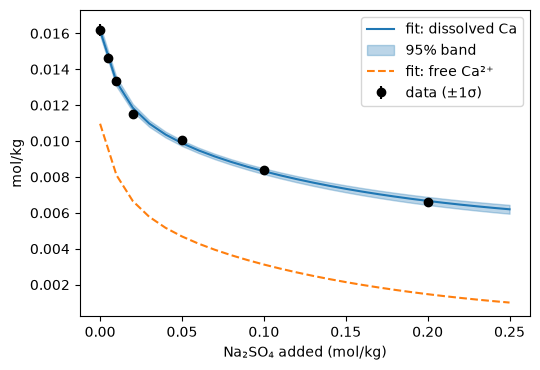

In [4]:
grid = np.linspace(0, 0.25, 26)
pred = np.array([res.predict(conditions(c), dissolved_ca) for c in grid])
free_ca = np.array([res.predict(conditions(c), "molality:Ca+2") for c in grid])
fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.errorbar(na2so4, measured, yerr=0.02 * measured, fmt="ko", label="data (±1σ)")
ax.plot(grid, pred[:, 0], "C0", label="fit: dissolved Ca")
ax.fill_between(grid, pred[:, 0] - 1.96 * pred[:, 1], pred[:, 0] + 1.96 * pred[:, 1], color="C0", alpha=0.3, label="95% band")
ax.plot(grid, free_ca[:, 0], "C1--", label="fit: free Ca²⁺")
ax.set(xlabel="Na₂SO₄ added (mol/kg)", ylabel="mol/kg")
ax.legend()
plt.tight_layout()

**Result.** The fit passes through all seven points. The 95 % band is narrow inside the data and widens slightly beyond 0.2 mol/kg, where there are no measurements. The gap between dissolved Ca and free Ca²⁺ is the CaSO₄⁰ ion pair. It stays at about 0.005 mol/kg at every sulfate level, so at 0.2 mol/kg Na₂SO₄ most dissolved calcium is paired.

### Profile likelihood

**Why.** The intervals in the summary are *linearized*: they assume the model is linear in the parameters near the best fit. A profile-likelihood interval does not ([Venzon & Moolgavkar 1988](https://doi.org/10.2307/2347496)).

**Method.** `res.profile(name)` fixes one parameter at each grid value, re-optimizes the others, and records the minimum $\chi^2$. With absolute σ the 95 % interval is where $\chi^2 \le \chi^2_{\min} + 3.84$ (the 95 % point of $\chi^2$ with one degree of freedom), the dashed line in the plots.

**Interpretation.** When the model is nearly linear, the profile and linearized intervals agree; when they disagree, trust the profile. A profile that never crosses the threshold means the data cannot bound that parameter ([Raue et al. 2009](https://doi.org/10.1093/bioinformatics/btp358)).

 INFO pounce::linesearch: theta_max raised 4.343e4 -> 4.343e6 (raise 1 of 4): 3 consecutive line searches had every trial rejected at the theta_max gate (pounce#546)


logK gypsum    linearized [-4.6014, -4.5443]   profile [-4.6021, -4.5453]


logK pair      linearized [2.2368, 2.3403]   profile [2.2368, 2.3400]


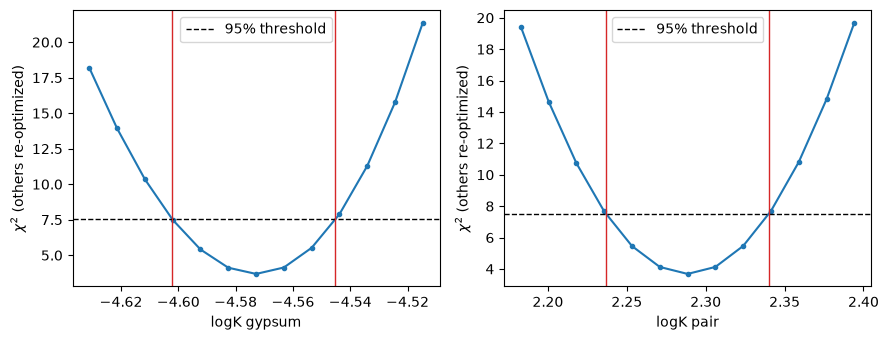

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, name in zip(axs, res.names):
    pr = res.profile(name, n=13)
    pr.plot(ax)
    lo, hi = res.confidence_intervals[name]
    print(f"{name:14s} linearized [{lo:.4f}, {hi:.4f}]   profile [{pr.interval[0]:.4f}, {pr.interval[1]:.4f}]")
plt.tight_layout()

**Result.** Both profiles are close to parabolas, and the profile and linearized intervals agree to within 0.001, so the linearized errors can be trusted here. The `INFO pounce::linesearch` line is a diagnostic from the inner optimizer, not an error.

### Asking for more than the data can tell

**Test.** Refit the same data with a third parameter, the Davies $b$ (the coefficient of the linear $bI$ term, 0.3 in truth). There is no ready-made helper for it, so it is a custom `fit.Parameter(name, set, get)`: `set` writes a value into the model and `get` reads it back. This pattern works for any number in the model.

**What to expect.** In these data $b$ and the ion-pair constant both raise solubility as ionic strength increases, so the data cannot tell them apart. The fit warns when the largest correlation exceeds |r| = 0.99, or when the sensitivity matrix is ill-conditioned (condition number above 10¹⁰).

In [6]:
model3 = gypsum_system()
davies_b = fit.Parameter("Davies b", set=lambda v: setattr(model3.activity, "b", v),
                         get=lambda: model3.activity.b, lower=-0.5, upper=1.0)
params3 = [fit.logK(model3, "gypsum", lower=-6, upper=-3), fit.logK(model3, "pair", lower=0, upper=4), davies_b]
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    res3 = fit.fit_equilibrium(model3, obs, params3, absolute_sigma=True)
print(res3.summary())
for w in caught:
    print("\nwarning:", w.message)
print("\nstandard error of logK pair: 2 parameters", round(res.standard_errors["logK pair"], 3),
      "-> 3 parameters", round(res3.standard_errors["logK pair"], 3))

fit: `ftol` termination condition is satisfied. (success=True, 134 model evaluations)
chi2 = 3.18401, dof = 4, reduced chi2 = 0.796 (sigma treated as absolute)
parameter                                value     std err   95% CI (linearized)
logK gypsum                            -4.5219       0.145   [-4.806, -4.2378]
logK pair                               2.1073       0.561   [1.0069, 3.2078]
Davies b                               0.20835       0.174   [-0.13312, 0.54982]
correlation:
  logK gypsum                     1.000 -0.999 -0.995
  logK pair                      -0.999  1.000  0.998
  Davies b                       -0.995  0.998  1.000


standard error of logK pair: 2 parameters 0.026 -> 3 parameters 0.561


**Result.**
- **The fit is still good** ($\chi^2/\text{dof} = 0.80$): a good fit does not mean well-determined parameters.
- **All three correlations exceed 0.99** in magnitude; the warning names only the largest (gypsum–pair, $r=-0.999$).
- **Intervals widen.** $b = 0.21 \pm 0.17$ (interval −0.13 to 0.55, which includes the true 0.3), and the standard error of $\log K_{pair}$ grows from 0.026 to 0.56, about 20 times.

**What would help.** Fix $b$ at a literature value, or add data that separate the effects, such as a different ionic medium (NaCl) that changes the ionic strength without changing sulfate. The `discopt-doe` plugin can choose such experiments systematically.

## 2. Temperature dependence: fitting logK and ΔH together

**Goal.** Section 1 worked at 25 °C. Here you fit how the gypsum constant changes with temperature.

**Data.** Gypsum solubility in pure water from 5 to 80 °C, with 1 % noise. The truth uses $\Delta H = -4$ kJ/mol; the fit starts from $\Delta H = 0$. The ion-pair constants are held at their true values.

**Model.** The van 't Hoff form $\log K(T) = \log K_{298} - \frac{\Delta H}{R\ln 10}\left(\frac1T - \frac1{298.15}\right)$, with both $\log K_{298}$ and $\Delta H$ fitted.

**Units.** `System.reaction(..., dH=...)` takes J/mol, while `fit.enthalpy` works in kJ/mol so its steps are comparable in size to $\log K$.

**Identifiability.** A wide temperature range is what makes $\Delta H$ identifiable; over a few kelvin, $\log K$ and $\Delta H$ would be almost perfectly correlated.

fit: `ftol` termination condition is satisfied. (success=True, 35 model evaluations)
chi2 = 0.677471, dof = 5, reduced chi2 = 0.1355 (sigma treated as absolute)
parameter                                value     std err   95% CI (linearized)
logK gypsum                            -4.5784     0.00235   [-4.583, -4.5738]
dH gypsum [kJ/mol]                     -4.1233       0.154   [-4.4246, -3.822]
correlation:
  logK gypsum                     1.000 -0.483
  dH gypsum [kJ/mol]             -0.483  1.000
truth: logK = -4.58, dH = -4.0 kJ/mol (the ion-pair constants are held at their true values)


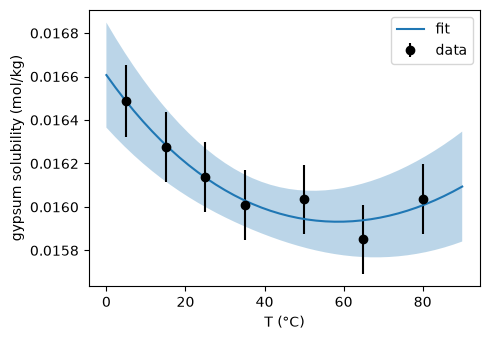

In [7]:
T_data = np.array([5, 15, 25, 35, 50, 65, 80]) + 273.15           # K
truthT = gypsum_system(dH=-4000.0)                                  # J/mol here; fit.enthalpy reports kJ/mol
yT = np.array([dissolved_ca(truthT.equilibrate(**conditions(0.0, T))) for T in T_data])
yT *= 1 + 0.01 * rng.normal(size=T_data.size)                       # 1 % measurement noise
modelT = gypsum_system(dH=0.0)
obsT = [fit.Observation(conditions(0.0, T), dissolved_ca, y, sigma=0.01 * y) for T, y in zip(T_data, yT)]
resT = fit.fit_equilibrium(modelT, obsT, [fit.logK(modelT, "gypsum", lower=-6, upper=-3),
                                          fit.enthalpy(modelT, "gypsum", lower=-50, upper=50)], absolute_sigma=True)
print(resT.summary())
print("truth: logK = -4.58, dH = -4.0 kJ/mol (the ion-pair constants are held at their true values)")

Tg = np.linspace(273.15, 363.15, 40)
band = np.array([resT.predict(conditions(0.0, T), dissolved_ca) for T in Tg])
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.errorbar(T_data - 273.15, yT, yerr=0.01 * yT, fmt="ko", label="data")
ax.plot(Tg - 273.15, band[:, 0], "C0", label="fit")
ax.fill_between(Tg - 273.15, band[:, 0] - 1.96 * band[:, 1], band[:, 0] + 1.96 * band[:, 1], alpha=0.3)
ax.set(xlabel="T (°C)", ylabel="gypsum solubility (mol/kg)"); ax.legend(); plt.tight_layout()

**Result.**
- **Recovery.** $\log K = -4.5784 \pm 0.0024$ and $\Delta H = -4.12 \pm 0.15$ kJ/mol, both within one standard error of the truth (−4.58, −4.0).
- **Correlation** is only −0.48, because the reference temperature (25 °C) lies inside the data range.
- **Low χ².** $\chi^2/\text{dof} = 0.14$ is below the expected ≈ 1; with only 7 points this can happen by chance.
- **The curve** passes through a shallow minimum near 60 °C: the model combines the negative $\Delta H$ of gypsum with the positive $\Delta H$ of the ion pair and temperature-dependent activity corrections. The band widens outside 5–80 °C, where the curve is extrapolated.

## 3. Fitting against a PHREEQC database: calcite in CO₂-bearing water

**Goal.** The same tools work on a full database system. Start from [`phreeqc.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/phreeqc.dat) ([Parkhurst & Appelo 2013](https://doi.org/10.3133/tm6A43)) and refit two of its constants to pH and dissolved-calcium measurements at eight CO₂ partial pressures:

- the calcite solubility product ($\log K \approx -8.48$ for CaCO₃ = CO₃²⁻ + Ca²⁺);
- the CaHCO₃⁺ stability constant ($\log K \approx 11.43$ for Ca²⁺ + CO₃²⁻ + H⁺ = CaHCO₃⁺, as written in the database).

**Conditions.** `"fixed": {"CO2(g)": lp}` holds $\log_{10} p_{\text{CO}_2}$ (atm) constant, like water open to a gas of that composition; excess calcite is present at every point. `fit.logK(...).get()` reads the current database value. Here those values generate the synthetic data, and `initial=` starts the fit elsewhere.

**Temperature dependence.** The database stores these constants as analytic functions of $T$. `fit.logK` shifts the constant term, so the fitted parameter is still $\log K$ at 25 °C and the database's temperature dependence is kept.

In [8]:
db = PhreeqcDatabase.load("phreeqc.dat")
cal = db.system(["Ca", "C(4)"], phases=["Calcite", "CO2(g)"])
ca_total = fit.total("Ca+2", "CaHCO3+", "CaCO3", "CaOH+")
# database log K values at 25 °C; they generate the synthetic data below
true_values = {"Calcite": fit.logK(cal, "Calcite").get(), "CaHCO3+": fit.logK(cal, "CaHCO3+").get()}

obs_cal = []
for lp in np.linspace(-4.5, -1.0, 8):
    cond = {"amounts": {"Calcite": 1.0}, "fixed": {"CO2(g)": lp}}
    r = cal.equilibrate(cond["amounts"], fixed=cond["fixed"])
    obs_cal.append(fit.Observation(cond, "pH", r.pH + rng.normal(0, 0.01), sigma=0.01))
    obs_cal.append(fit.Observation(cond, ca_total, ca_total(r) * (1 + 0.02 * rng.normal()), sigma=0.02 * ca_total(r)))

p_cal = [fit.logK(cal, "Calcite", initial=-8.0, lower=-10, upper=-6), fit.logK(cal, "CaHCO3+", initial=10.5, lower=8, upper=14)]
res_cal = fit.fit_equilibrium(cal, obs_cal, p_cal, absolute_sigma=True)
print(res_cal.summary())
print("database values used to generate the data:", {k: round(v, 4) for k, v in true_values.items()})

fit: `ftol` termination condition is satisfied. (success=True, 52 model evaluations)
chi2 = 14.4726, dof = 14, reduced chi2 = 1.034 (sigma treated as absolute)
parameter                                value     std err   95% CI (linearized)
logK Calcite                           -8.4857     0.00938   [-8.5041, -8.4673]
logK CaHCO3+                            11.428       0.226   [10.984, 11.871]
correlation:
  logK Calcite                    1.000 -0.719
  logK CaHCO3+                   -0.719  1.000
database values used to generate the data: {'Calcite': -8.4798, 'CaHCO3+': 11.4347}


**Result.**
- **Recovery.** $\log K_{\text{Calcite}} = -8.486 \pm 0.009$ (database −8.480) and $\log K_{\text{CaHCO}_3^+} = 11.43 \pm 0.23$ (database 11.435), both within one standard error.
- **Goodness of fit.** $\chi^2/\text{dof} = 1.03$ with 16 observations (8 pH, 8 calcium).
- **CaHCO₃⁺ is less certain.** Its standard error is about 25 times the calcite one because CaHCO₃⁺ is a minor species, so the data are only weakly sensitive to it. The correlation ($r = -0.72$) is moderate: the two constants are separable.

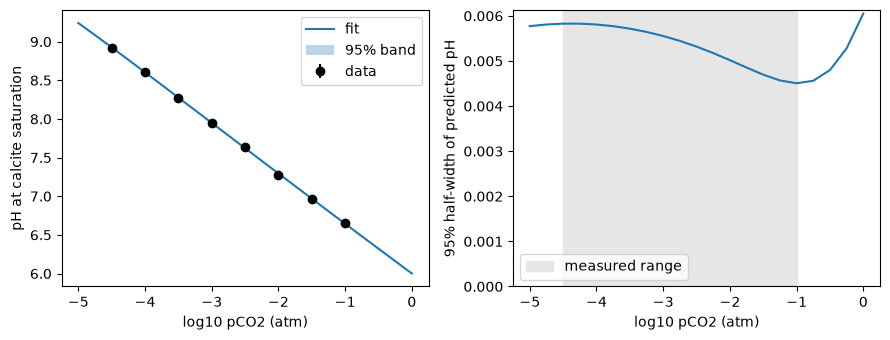

In [9]:
lps = np.linspace(-5, 0, 21)
pH_band = np.array([res_cal.predict({"amounts": {"Calcite": 1.0}, "fixed": {"CO2(g)": lp}}, "pH") for lp in lps])
data_lp = [o.conditions["fixed"]["CO2(g)"] for o in obs_cal if o.quantity == "pH"]
data_pH = [o.value for o in obs_cal if o.quantity == "pH"]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))
ax.errorbar(data_lp, data_pH, yerr=0.01, fmt="ko", label="data")
ax.plot(lps, pH_band[:, 0], "C0", label="fit")
ax.fill_between(lps, pH_band[:, 0] - 1.96 * pH_band[:, 1], pH_band[:, 0] + 1.96 * pH_band[:, 1], alpha=0.3, label="95% band")
ax.set(xlabel="log10 pCO2 (atm)", ylabel="pH at calcite saturation"); ax.legend()
# the band is thinner than the line on the left, so show its half-width directly
ax2.plot(lps, 1.96 * pH_band[:, 1], "C0")
ax2.axvspan(min(data_lp), max(data_lp), color="0.9", label="measured range")
ax2.set(xlabel="log10 pCO2 (atm)", ylabel="95% half-width of predicted pH", ylim=(0, None)); ax2.legend()
plt.tight_layout()

**Result.** The predicted pH at calcite saturation falls linearly with $\log p_{\text{CO}_2}$ through all the data. The 95 % band is too narrow to see on the left, so the right panel plots its half-width: about 0.005 pH units, smallest inside the measured range near $\log p_{\text{CO}_2} = -1$ and rising to 0.006 when extrapolated to 1 atm.

## Summary

| step | call |
|------|------|
| choose what to fit | `fit.logK`, `fit.enthalpy`, `fit.activity_parameter`, or `fit.Parameter(name, set, get)` |
| describe measurements | `fit.Observation(conditions, quantity, value, sigma)`, where the quantity is `"pH"`, `"SI:Gypsum"`, `fit.total(...)`, a callable, ... |
| fit | `res = fit.fit_equilibrium(system, observations, parameters, absolute_sigma=...)` |
| uncertainty | `res.summary()`, `res.confidence_intervals`, `res.correlation`, `res.profile(name)` |
| use the result | the system now holds the fitted values; `res.predict(conditions, quantity)` gives value ± standard error |

**Take-aways.**
- Warnings about ill-conditioning, strong correlation or non-converged points mean the data do not determine the parameters as posed: fix a parameter or add more informative data.
- A good $\chi^2$ does not guarantee well-determined parameters; check correlations and profiles.
- For concentrations spanning decades, fit `"log10_molality:..."` with a constant `sigma`.

## Next steps

- [`docs/fitting.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/fitting.md): all parameter helpers, observation quantities, and practical advice (cost, held-out validation).
- [`docs/activity-models.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/activity-models.md): the activity models whose parameters you can fit.
- Notebook 05 draws speciation and phase diagrams from a model; notebook 06 applies the package to rare earths and thorium.

## References

- Davies, C.W. (1938). The extent of dissociation of salts in water. Part VIII. *J. Chem. Soc.*, 2093. [doi:10.1039/JR9380002093](https://doi.org/10.1039/JR9380002093)
- Parkhurst, D.L., and Appelo, C.A.J. (2013). Description of input and examples for PHREEQC version 3. USGS Techniques and Methods 6-A43. [doi:10.3133/tm6A43](https://doi.org/10.3133/tm6A43)
- Venzon, D.J., and Moolgavkar, S.H. (1988). A method for computing profile-likelihood-based confidence intervals. *Applied Statistics* 37, 87–94. [doi:10.2307/2347496](https://doi.org/10.2307/2347496)
- Raue, A., Kreutz, C., Maiwald, T., Bachmann, J., Schilling, M., Klingmüller, U., and Timmer, J. (2009). Structural and practical identifiability analysis of partially observed dynamical models by exploiting the profile likelihood. *Bioinformatics* 25, 1923–1929. [doi:10.1093/bioinformatics/btp358](https://doi.org/10.1093/bioinformatics/btp358)

The full bibliography is in [`docs/references.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/references.md).